<a href="https://colab.research.google.com/github/sauravpatil045/MLOPS1.THIRD-YEAR/blob/main/MIL6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [211]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix,classification_report

In [212]:
data = pd.read_csv('Hamspam.csv', encoding='latin-1')
df = pd.DataFrame(data)
print(df)

      type                                               text
0      ham  Hope you are having a good week. Just checking in
1      ham                            K..give back my thanks.
2      ham        Am also doing in cbe only. But have to pay.
3     spam  complimentary 4 STAR Ibiza Holiday or å£10,000...
4     spam  okmail: Dear Dave this is your final notice to...
...    ...                                                ...
5554   ham  You are a great role model. You are giving so ...
5555   ham  Awesome, I remember the last time we got someb...
5556  spam  If you don't, your prize will go to another cu...
5557  spam  SMS. ac JSco: Energy is high, but u may not kn...
5558   ham                    Shall call now dear having food

[5559 rows x 2 columns]


In [213]:
df.describe()

,type,text
count,5559,5559
unique,2,5156
top,ham,"Sorry, I'll call later"
freq,4812,30


In [214]:
df.duplicated().sum()

np.int64(403)

In [215]:
df=df.drop_duplicates()

In [216]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 5156 entries, 0 to 5558
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   type    5156 non-null   object
 1   text    5156 non-null   object
dtypes: object(2)
memory usage: 120.8+ KB


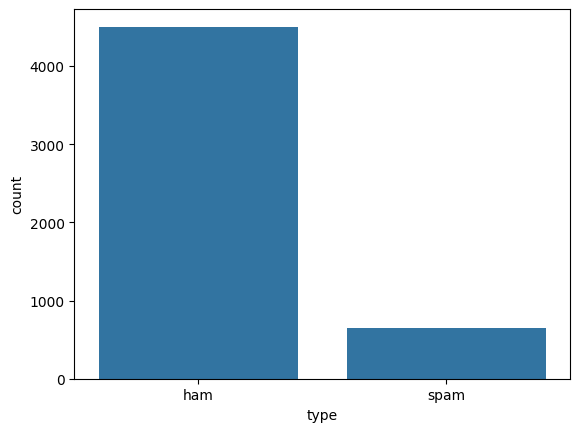

In [217]:
sns.countplot(x = df['type'])
plt.show()

In [218]:
from sklearn.feature_extraction.text import TfidfVectorizer
vectorizer = TfidfVectorizer()

x = vectorizer.fit_transform(df["text"]).toarray()
y = df["type"]
print("Feature shape:", x.shape)

Feature shape: (5156, 8698)


In [219]:
x_train, x_test, y_train, y_test = train_test_split (x, y,
  test_size=0.25,
  random_state=42,
  stratify=y)

In [220]:
from sklearn.naive_bayes import MultinomialNB
model = MultinomialNB()
model.fit(x_train, y_train)

MultinomialNB()

In [221]:
y_pred = model.predict(x_test)
print("Predictions:", y_pred[:20])

Predictions: ['ham' 'ham' 'ham' 'ham' 'ham' 'ham' 'ham' 'ham' 'ham' 'ham' 'ham' 'spam'
 'ham' 'ham' 'spam' 'ham' 'ham' 'ham' 'ham' 'ham']


In [222]:
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)

Accuracy: 0.9557796741660202


In [223]:
cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[1126    0]
 [  57  106]]


In [224]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

         ham       0.95      1.00      0.98      1126
        spam       1.00      0.65      0.79       163

    accuracy                           0.96      1289
   macro avg       0.98      0.83      0.88      1289
weighted avg       0.96      0.96      0.95      1289



In [225]:
new_email = ["You have meeting today"]
new_email_vector = vectorizer.transform(new_email).toarray()
prediction = model.predict(new_email_vector)
print("Email:", new_email[0])
print("Prediction:", prediction[0])


Email: You have meeting today
Prediction: ham
